In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

In [2]:
import kagglehub
path = kagglehub.dataset_download("nextmillionaire/car-accident-dataset")


100%|██████████| 7.06M/7.06M [00:00<00:00, 67.2MB/s]

Extracting files...


## **DataShape**

In [3]:
import os

file_path = os.path.join(path, "Road Accident Data.csv")
df = pd.read_csv(file_path)

df.head()
df.shape
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (307973, 21)


,Accident_Index,Accident Date,Day_of_Week,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,...,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200901BS70001,1/1/2021,Thursday,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Dry,One way street,30,15:11,Urban,Fine no high winds,Car
1,200901BS70002,1/5/2021,Monday,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,NaN,...,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59,Urban,Fine no high winds,Taxi/Private hire car
2,200901BS70003,1/4/2021,Sunday,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19,Urban,Fine no high winds,Taxi/Private hire car
3,200901BS70004,1/5/2021,Monday,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,8:10,Urban,Other,Motorcycle over 500cc
4,200901BS70005,1/6/2021,Tuesday,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25,Urban,Fine no high winds,Car


# **Data Inspection**

## **DataType**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307973 entries, 0 to 307972
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Accident_Index              307973 non-null  object 
 1   Accident Date               307973 non-null  object 
 2   Day_of_Week                 307973 non-null  object 
 3   Junction_Control            307973 non-null  object 
 4   Junction_Detail             307973 non-null  object 
 5   Accident_Severity           307973 non-null  object 
 6   Latitude                    307973 non-null  float64
 7   Light_Conditions            307973 non-null  object 
 8   Local_Authority_(District)  307973 non-null  object 
 9   Carriageway_Hazards         5424 non-null    object 
 10  Longitude                   307973 non-null  float64
 11  Number_of_Casualties        307973 non-null  int64  
 12  Number_of_Vehicles          307973 non-null  int64  
 13  Police_Force  

In [5]:
df.describe()

,Latitude,Longitude,Number_of_Casualties,Number_of_Vehicles,Speed_limit
count,307973.000000,307973.000000,307973.000000,307973.000000,307973.000000
mean,52.487005,-1.368884,1.356882,1.829063,38.866037
std,1.339011,1.356092,0.815857,0.710477,14.032933
min,49.914488,-7.516225,1.000000,1.000000,10.000000
25%,51.485248,-2.247937,1.000000,1.000000,30.000000
50%,52.225943,-1.349258,1.000000,2.000000,30.000000
75%,53.415517,-0.206810,1.000000,2.000000,50.000000
max,60.598055,1.759398,48.000000,32.000000,70.000000


## **Missing values**

In [6]:
df.isnull().sum()

,0
Accident_Index,0
Accident Date,0
Day_of_Week,0
Junction_Control,0
Junction_Detail,0
Accident_Severity,0
Latitude,0
Light_Conditions,0
Local_Authority_(District),0
Carriageway_Hazards,302549


In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

missing_df = missing_df[missing_df['Missing Count'] > 0] \
                .sort_values('Missing %', ascending=False)

print(missing_df)

                         Missing Count  Missing %
Carriageway_Hazards             302549       98.2
Weather_Conditions                6057        2.0
Road_Type                         1534        0.5
Road_Surface_Conditions            317        0.1
Time                                17        0.0


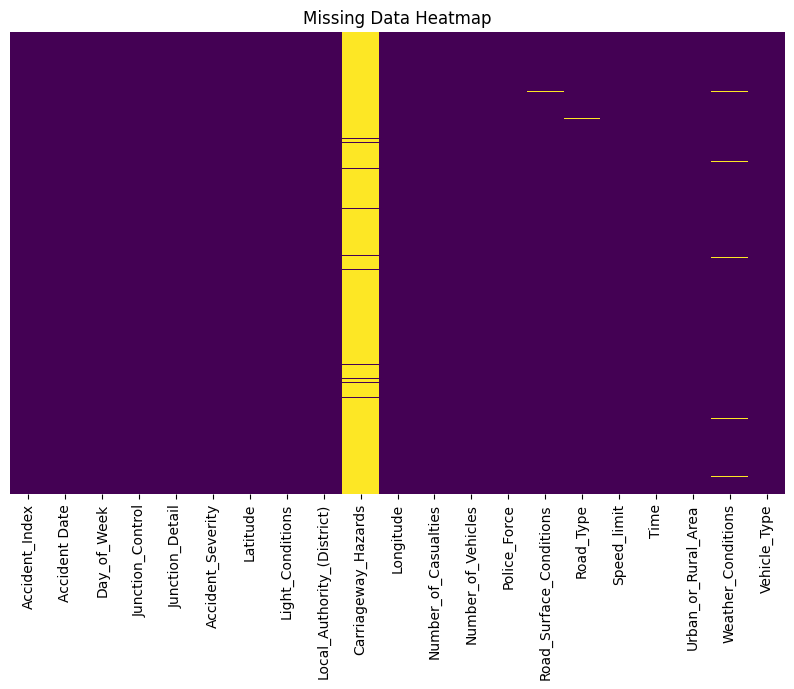

In [8]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(),
            cbar=False,
            cmap='viridis',
            yticklabels=False)
plt.title("Missing Data Heatmap")
plt.show()

# **MCAR vs MAR Analysis**

In [9]:
df['Hazards_Missing'] = df['Carriageway_Hazards'].isnull().astype(int)

df['Hazards_Missing'].value_counts()

missing_pct = df['Hazards_Missing'].mean() * 100
print("Hazards Missing %:", round(missing_pct, 2), "%")

numeric_cols = ['Speed_limit', 'Number_of_Vehicles', 'Number_of_Casualties']

for col in numeric_cols:
    corr, p = stats.pointbiserialr(df['Hazards_Missing'], df[col])
    print(f"{col} p-value:", p)


Hazards Missing %: 98.24 %
Speed_limit p-value: 0.0
Number_of_Vehicles p-value: 1.3376075675405196e-39
Number_of_Casualties p-value: 0.0018646556897666052


### **Data Cleaning:** Carriageway_Hazards Was removed due to excessive missing values

In [10]:
df = df.drop(columns=['Carriageway_Hazards'])
for col in df.select_dtypes(include='object').columns:
    df[col].fillna(df[col].mode()[0], inplace=True)



df.isnull().sum()

,0
Accident_Index,0
Accident Date,0
Day_of_Week,0
Junction_Control,0
Junction_Detail,0
Accident_Severity,0
Latitude,0
Light_Conditions,0
Local_Authority_(District),0
Longitude,0


In [11]:
df['Accident_Severity'] = df['Accident_Severity'].replace('Fetal', 'Fatal')

### **EDA**

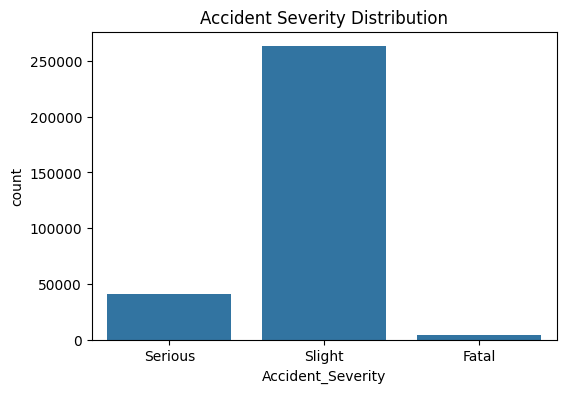

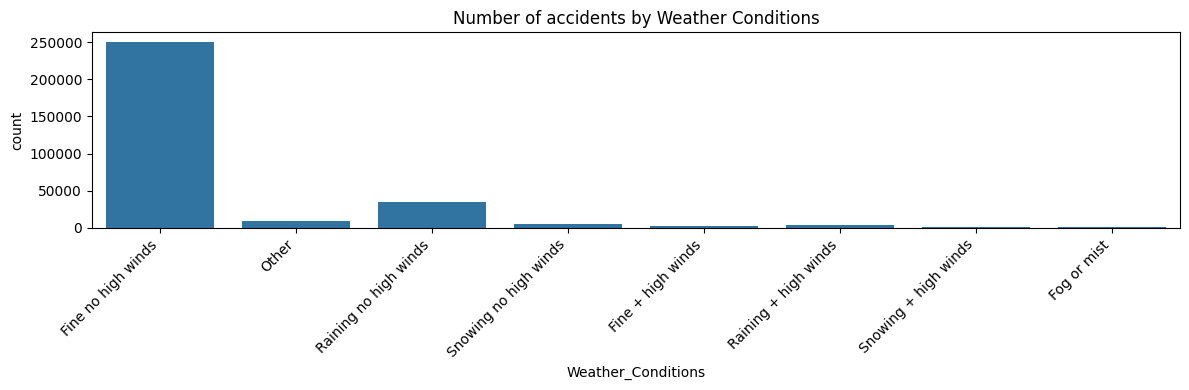

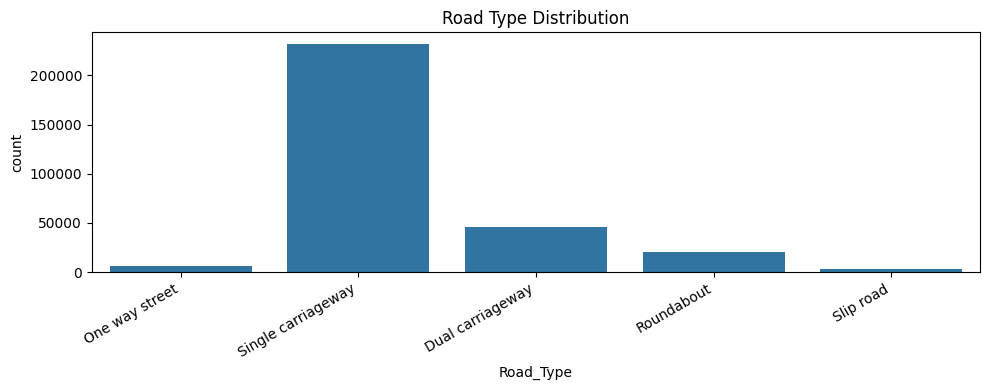

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x='Accident_Severity', data=df)
plt.title('Accident Severity Distribution')
plt.show()

plt.figure(figsize=(12,4))
sns.countplot(x='Weather_Conditions', data=df)
plt.xticks(rotation=45, ha='right')
plt.title('Number of accidents by Weather Conditions')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4))
sns.countplot(x='Road_Type', data=df)
plt.xticks(rotation=30, ha='right')
plt.title('Road Type Distribution')
plt.tight_layout()
plt.show()

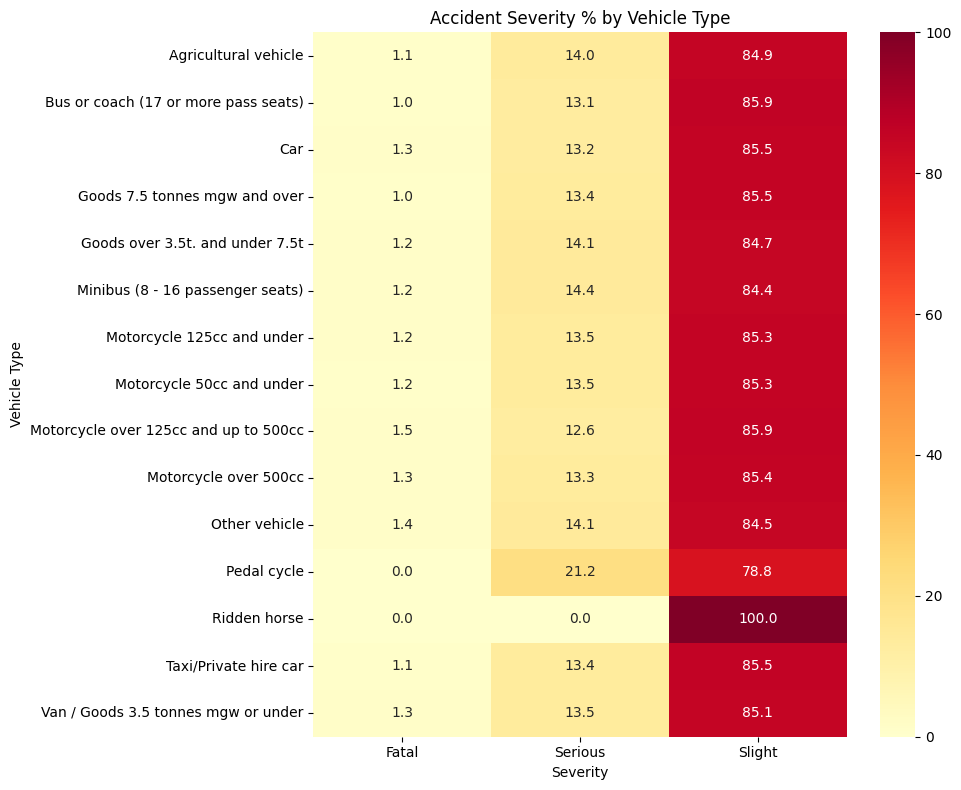

In [13]:
ct = pd.crosstab(df['Vehicle_Type'], df['Accident_Severity'], normalize='index') * 100

plt.figure(figsize=(10, 8))
sns.heatmap(ct, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Accident Severity % by Vehicle Type')
plt.xlabel('Severity')
plt.ylabel('Vehicle Type')
plt.tight_layout()
plt.show()

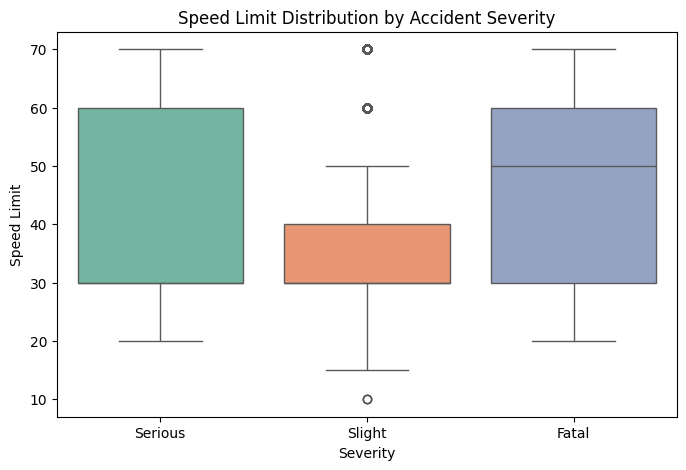

In [14]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Accident_Severity', y='Speed_limit', data=df, palette='Set2')
plt.title('Speed Limit Distribution by Accident Severity')
plt.xlabel('Severity')
plt.ylabel('Speed Limit')
plt.show()

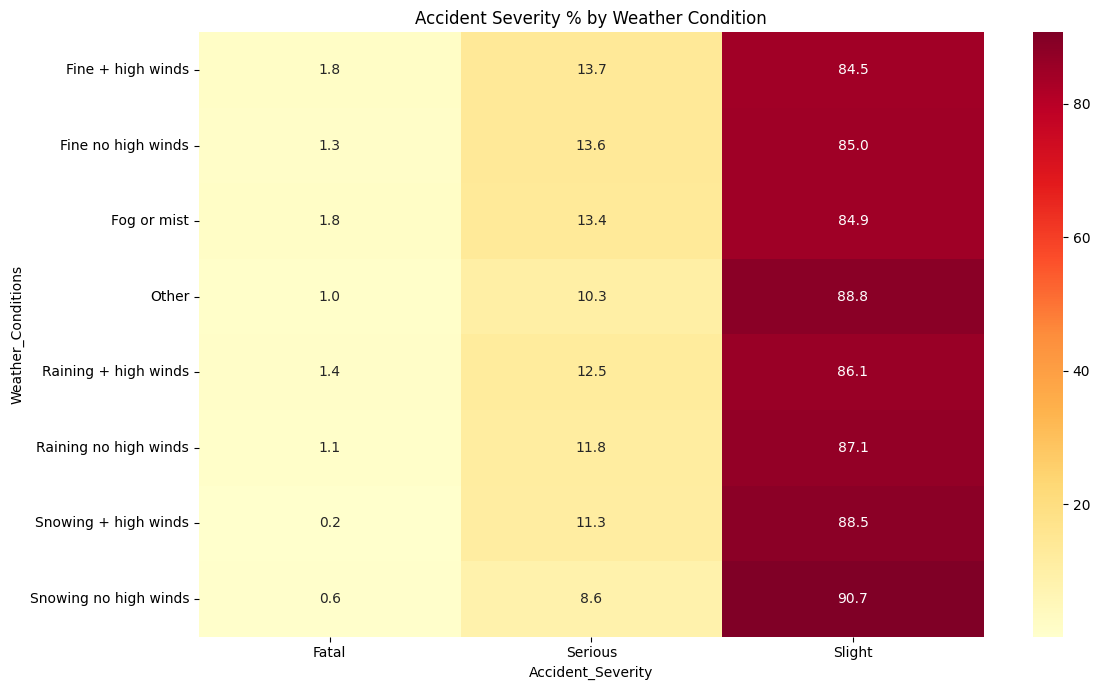

In [15]:
ct_weather = pd.crosstab(df['Weather_Conditions'], df['Accident_Severity'], normalize='index') * 100

plt.figure(figsize=(12, 7))
sns.heatmap(ct_weather, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Accident Severity % by Weather Condition')
plt.tight_layout()
plt.show()

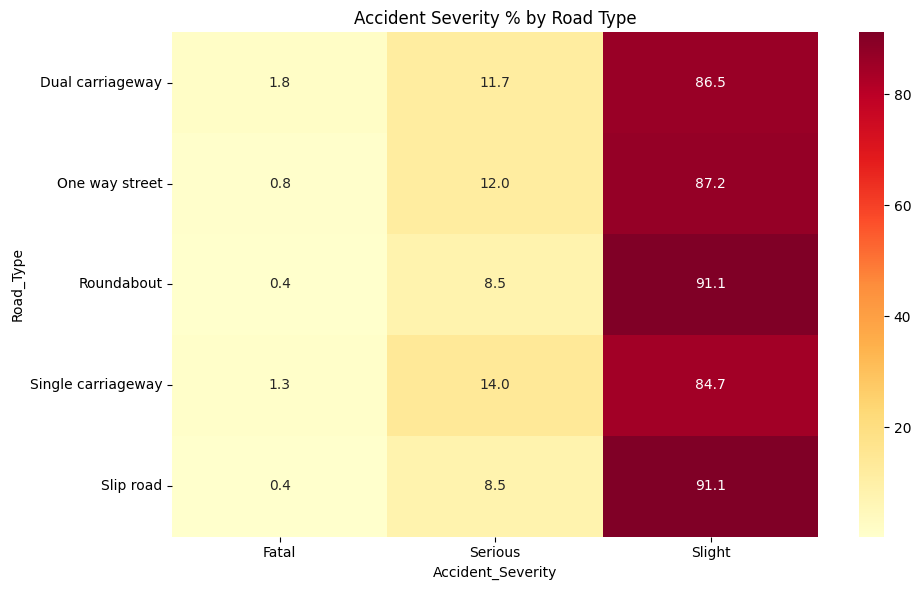

In [16]:
ct_road = pd.crosstab(df['Road_Type'], df['Accident_Severity'], normalize='index') * 100

plt.figure(figsize=(10, 6))
sns.heatmap(ct_road, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Accident Severity % by Road Type')
plt.tight_layout()
plt.show()

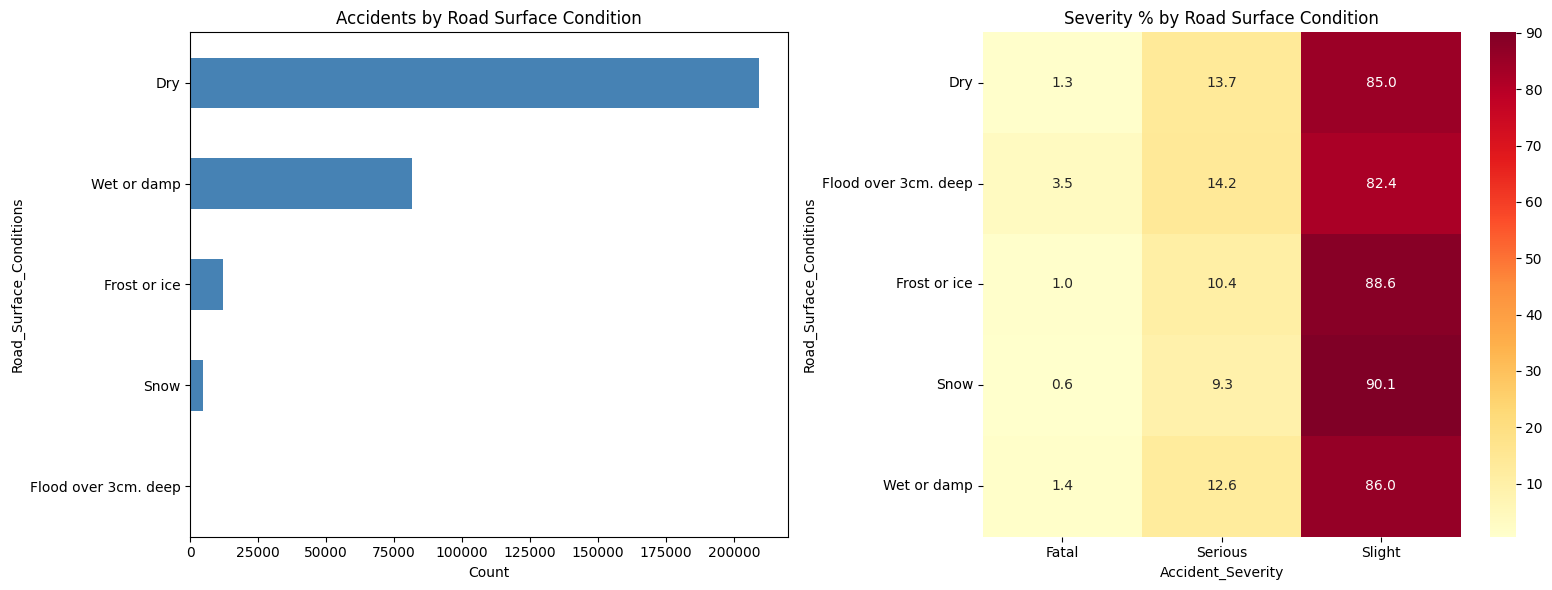

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

road_counts = df['Road_Surface_Conditions'].value_counts()
road_counts.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Accidents by Road Surface Condition')
axes[0].set_xlabel('Count')
axes[0].invert_yaxis()

ct_surface = pd.crosstab(df['Road_Surface_Conditions'],
                          df['Accident_Severity'],
                          normalize='index') * 100
sns.heatmap(ct_surface, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1])
axes[1].set_title('Severity % by Road Surface Condition')

plt.tight_layout()
plt.show()

#Feature Engineering

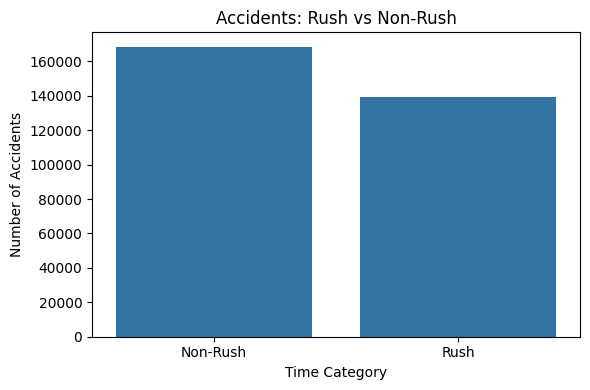

In [18]:


df['Hour'] = pd.to_datetime(df['Time'], errors='coerce').dt.hour


df = df.dropna(subset=['Hour'])
df['Hour'] = df['Hour'].astype(int)


df['Rush_Category'] = df['Hour'].apply(
    lambda h: 'Rush' if (7 <= h <= 9 or 16 <= h <= 19) else 'Non-Rush'
)


plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Rush_Category', order=['Non-Rush', 'Rush'])
plt.title('Accidents: Rush vs Non-Rush')
plt.xlabel('Time Category')
plt.ylabel('Number of Accidents')
plt.tight_layout()
plt.show()


df['Is_Rush_Hour'] = (df['Rush_Category'] == 'Rush').astype(int)


df = df.drop(columns=['Time'])

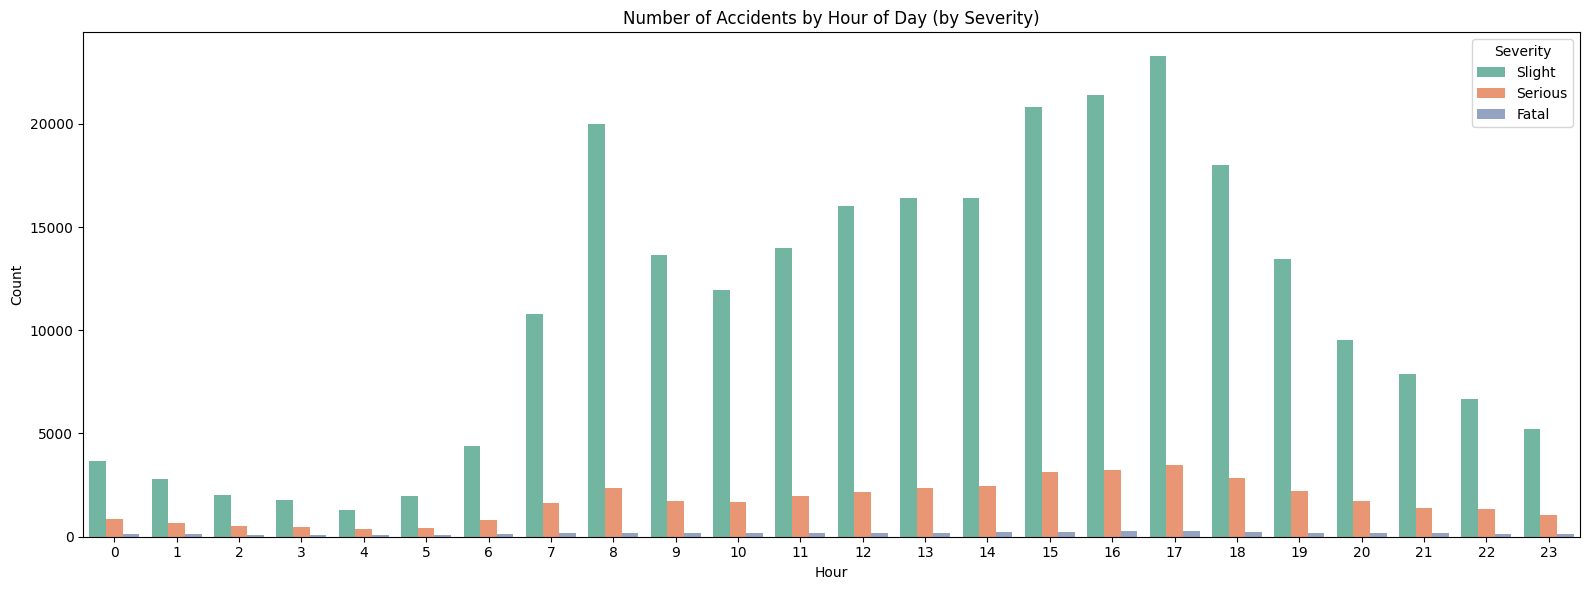

In [19]:
plt.figure(figsize=(16, 6))
sns.countplot(x='Hour', hue='Accident_Severity', data=df, palette='Set2')
plt.title('Number of Accidents by Hour of Day (by Severity)')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.legend(title='Severity')
plt.tight_layout()
plt.show()

## **weather feature engineer**

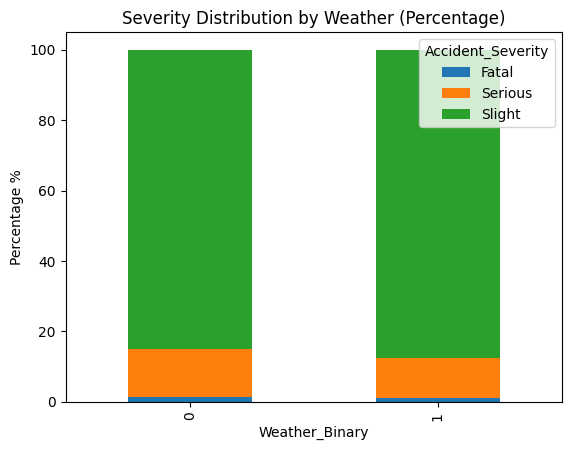

In [20]:
def classify_weather(x):
    if pd.isna(x):
        return "Bad"

    x = x.lower()

    if "fine" in x:
        return "Good"
    else:
        return "Bad"

df['Weather_Binary'] = df['Weather_Conditions'].apply(classify_weather)

df['Weather_Binary'] = df['Weather_Binary'].map({
    "Good": 0,
    "Bad": 1
})
severity_weather_pct = pd.crosstab(
    df['Weather_Binary'],
    df['Accident_Severity'],
    normalize='index'
) * 100

severity_weather_pct
severity_weather_pct.plot(kind='bar', stacked=True)
plt.title("Severity Distribution by Weather (Percentage)")
plt.ylabel("Percentage %")
plt.show()



X and Y

In [21]:
X = df.drop('Accident_Severity', axis=1)
y = df['Accident_Severity']

**Train** / **Test Split**

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# **CatBoost**

In [23]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.5 MB/s eta 0:00:00


In [24]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("Categorical Features:")
print(categorical_cols)

Categorical Features:
['Accident_Index', 'Accident Date', 'Day_of_Week', 'Junction_Control', 'Junction_Detail', 'Light_Conditions', 'Local_Authority_(District)', 'Police_Force', 'Road_Surface_Conditions', 'Road_Type', 'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type', 'Rush_Category']


In [25]:
from catboost import CatBoostClassifier


model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=4,
    loss_function='MultiClass',
    eval_metric='Accuracy',
    auto_class_weights='Balanced',
    random_state=42,
    verbose=50,
    early_stopping_rounds=20
)


model.fit(
    X_train,
    y_train,
    cat_features=categorical_cols,
    eval_set=(X_test, y_test)
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))



0:	learn: 0.4755487	test: 0.4716275	best: 0.4716275 (0)	total: 1.83s	remaining: 3m
50:	learn: 0.5099587	test: 0.5044086	best: 0.5044086 (50)	total: 38.4s	remaining: 36.9s
99:	learn: 0.5133732	test: 0.5068736	best: 0.5080001 (94)	total: 1m	remaining: 0us

bestTest = 0.5080001025
bestIteration = 94

Shrink model to first 95 iterations.
Accuracy: 0.5439240198068025

Classification Report:
               precision    recall  f1-score   support

       Fatal       0.04      0.62      0.07       791
     Serious       0.18      0.32      0.23      8148
      Slight       0.91      0.58      0.71     52656

    accuracy                           0.54     61595
   macro avg       0.38      0.51      0.34     61595
weighted avg       0.80      0.54      0.63     61595



# **Evaluation**

# **Feature Importance**

Accuracy: 0.5439240198068025

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.04      0.62      0.07       791
     Serious       0.18      0.32      0.23      8148
      Slight       0.91      0.58      0.71     52656

    accuracy                           0.54     61595
   macro avg       0.38      0.51      0.34     61595
weighted avg       0.80      0.54      0.63     61595



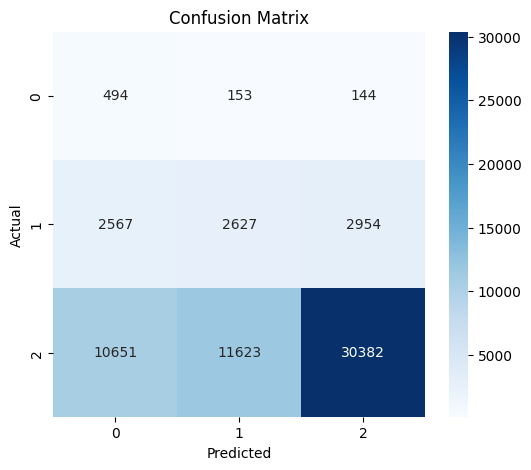

In [26]:

y_pred = model.predict(X_test)


print("Accuracy:", accuracy_score(y_test, y_pred))


print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Top 10 Important Features:
                       Feature  Importance
14                 Speed_limit   22.674243
10          Number_of_Vehicles   17.213375
7   Local_Authority_(District)   11.316542
9         Number_of_Casualties    8.445280
13                   Road_Type    5.811961
11                Police_Force    5.654940
15         Urban_or_Rural_Area    4.345139
19                        Hour    4.218383
6             Light_Conditions    3.801379
3             Junction_Control    3.657610


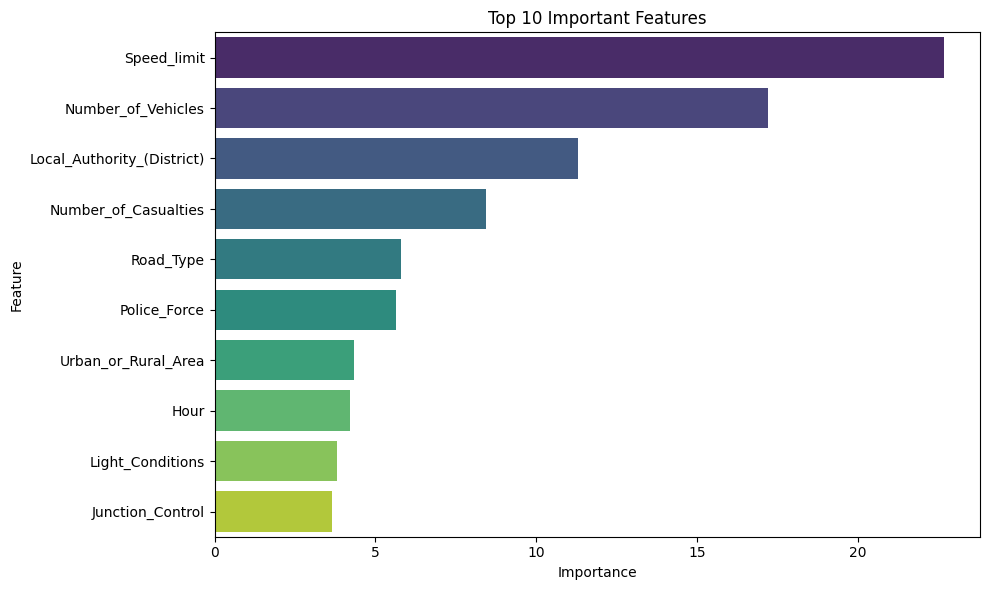

In [27]:

feature_importance = model.get_feature_importance()
feature_names = X_train.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)


print("Top 10 Important Features:")
print(importance_df.head(10))

plt.figure(figsize=(10,6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df.head(10),
    palette='viridis'
)
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()